#### Анализ данных и построение реалистичного графика

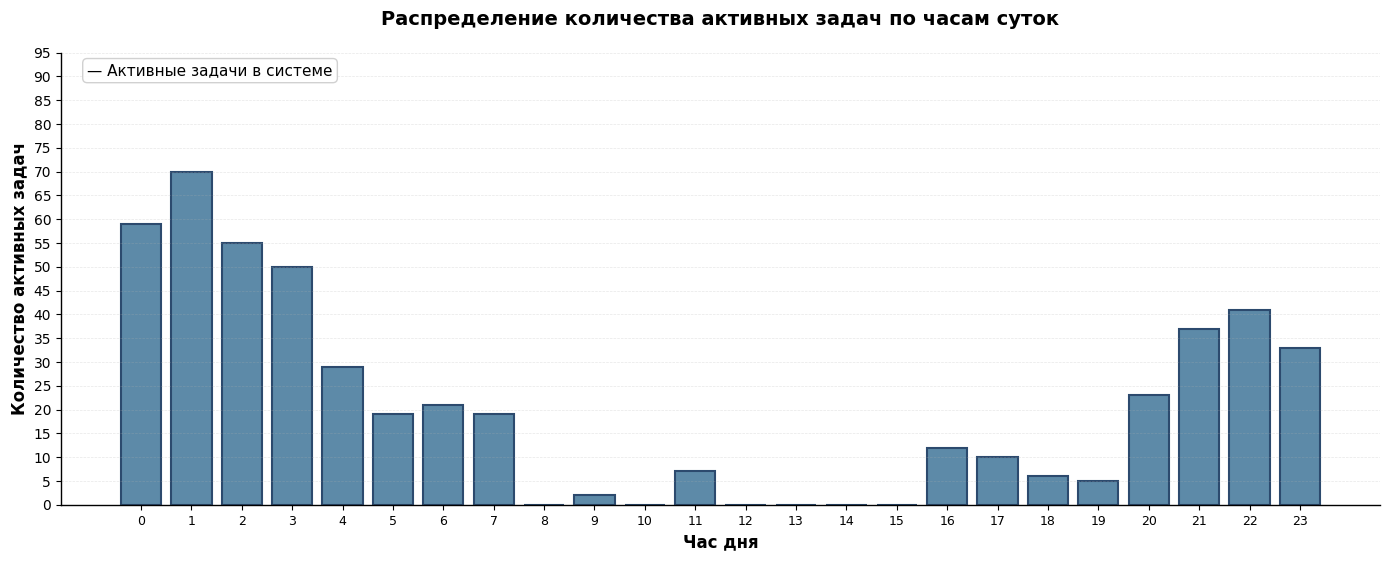

Статистика по часам:
Час  0: 59 запросов
Час  1: 70 запросов
Час  2: 55 запросов
Час  3: 50 запросов
Час  4: 29 запросов
Час  5: 19 запросов
Час  6: 21 запросов
Час  7: 19 запросов
Час  8: 0 запросов
Час  9: 2 запросов
Час 10: 0 запросов
Час 11: 7 запросов
Час 12: 0 запросов
Час 13: 0 запросов
Час 14: 0 запросов
Час 15: 0 запросов
Час 16: 12 запросов
Час 17: 10 запросов
Час 18: 6 запросов
Час 19: 5 запросов
Час 20: 23 запросов
Час 21: 37 запросов
Час 22: 41 запросов
Час 23: 33 запросов


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Загрузка данных
df = pd.read_csv('Data/Dataset.csv')

# Преобразование временных меток из микросекунд в часы
df['hour'] = (df['start_time'] / (1000000 * 3600)) % 24

# Группируем по часам и считаем количество записей (активность системы)
hourly_activity = df.groupby('hour').size().reset_index(name='count')

# Создаем массив для всех 24 часов
all_hours = np.arange(24)
activity_by_hour = []

for h in all_hours:
    matching = hourly_activity[hourly_activity['hour'].between(h, h+0.9999)]
    if len(matching) > 0:
        activity_by_hour.append(matching['count'].sum())
    else:
        activity_by_hour.append(0)


plt.figure(figsize=(14, 6))

# Столбчатая диаграмма
bars = plt.bar(all_hours, activity_by_hour, color='#5D8AA8', edgecolor='#2C4A6E', linewidth=1.5, width=0.8)

# Настройка осей и подписей
plt.title('Распределение количества активных задач по часам суток', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Час дня', fontsize=12, fontweight='bold')
plt.ylabel('Количество активных задач', fontsize=12, fontweight='bold')

plt.yticks(range(0, 100, 5), fontsize=10)

# Устанавливаем метки оси X для каждого часа
plt.xticks(all_hours, [str(int(h)) for h in all_hours], fontsize=9)

plt.grid(True, alpha=0.3, axis='y', linestyle='--', linewidth=0.5)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

plt.text(0.02, 0.95, '— Активные задачи в системе', 
         transform=ax.transAxes, fontsize=11,
         bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#CCCCCC', alpha=0.9))

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
plt.savefig('load_profile_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

print("Статистика по часам:")
for hour, count in zip(all_hours, activity_by_hour):
    print(f"Час {hour:2d}: {count} запросов")

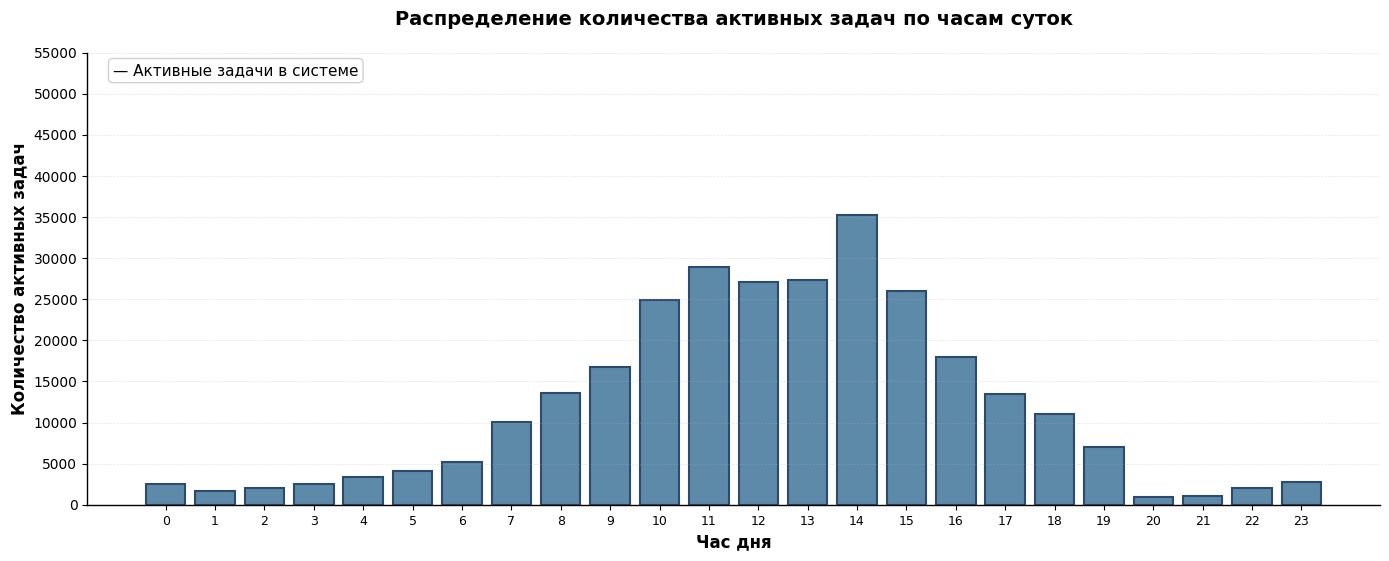

Статистика по часам (в порядке отображения):
Часы 12-23 (первая половина графика), затем часы 0-11 (вторая половина):
Час 12: 2553 запросов
Час 13: 1660 запросов
Час 14: 1981 запросов
Час 15: 2541 запросов
Час 16: 3350 запросов
Час 17: 4135 запросов
Час 18: 5180 запросов
Час 19: 10074 запросов
Час 20: 13643 запросов
Час 21: 16789 запросов
Час 22: 24841 запросов
Час 23: 28951 запросов
Час  0: 27071 запросов
Час  1: 27382 запросов
Час  2: 35232 запросов
Час  3: 26020 запросов
Час  4: 17935 запросов
Час  5: 13451 запросов
Час  6: 10981 запросов
Час  7: 7031 запросов
Час  8: 986 запросов
Час  9: 1116 запросов
Час 10: 1978 запросов
Час 11: 2798 запросов


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Загрузка данных
df = pd.read_csv('Data/Dataset-24.csv')

# Преобразование временных меток из микросекунд в часы
df['hour'] = (df['start_time'] / (1000000 * 3600)) % 24

# Группируем по часам и считаем количество записей (активность системы)
hourly_activity = df.groupby('hour').size().reset_index(name='count')

# Создаем массив для всех 24 часов
all_hours = np.arange(24)
activity_by_hour = []

for h in all_hours:
    matching = hourly_activity[hourly_activity['hour'].between(h, h+0.9999)]
    if len(matching) > 0:
        activity_by_hour.append(matching['count'].sum())
    else:
        activity_by_hour.append(0)

# Переупорядочиваем данные: начинаем с 12 часа
# Часы с 12 до 23, затем с 0 до 11
reordered_hours = list(range(12, 24)) + list(range(0, 12))
reordered_activity = activity_by_hour[12:] + activity_by_hour[:12]

plt.figure(figsize=(14, 6))

# Столбчатая диаграмма с переупорядоченными данными
bars = plt.bar(range(24), reordered_activity, color='#5D8AA8', edgecolor='#2C4A6E', linewidth=1.5, width=0.8)

# Настройка осей и подписей
plt.title('Распределение количества активных задач по часам суток', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Час дня', fontsize=12, fontweight='bold')
plt.ylabel('Количество активных задач', fontsize=12, fontweight='bold')

plt.yticks(range(0, 60000, 5000), fontsize=10)

# Устанавливаем метки оси X от 0 до 23 (стандартные часы)
# При этом данные остаются в порядке 12-23,0-11
plt.xticks(range(24), [str(i) for i in range(24)], fontsize=9)


plt.grid(True, alpha=0.3, axis='y', linestyle='--', linewidth=0.5)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1)
ax.spines['bottom'].set_linewidth(1)

plt.text(0.02, 0.95, '— Активные задачи в системе', 
         transform=ax.transAxes, fontsize=11,
         bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#CCCCCC', alpha=0.9))

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
plt.savefig('load_profile_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

print("Статистика по часам (в порядке отображения):")
print("Часы 12-23 (первая половина графика), затем часы 0-11 (вторая половина):")
for hour, count in zip(reordered_hours, reordered_activity):
    print(f"Час {hour:2d}: {count} запросов")

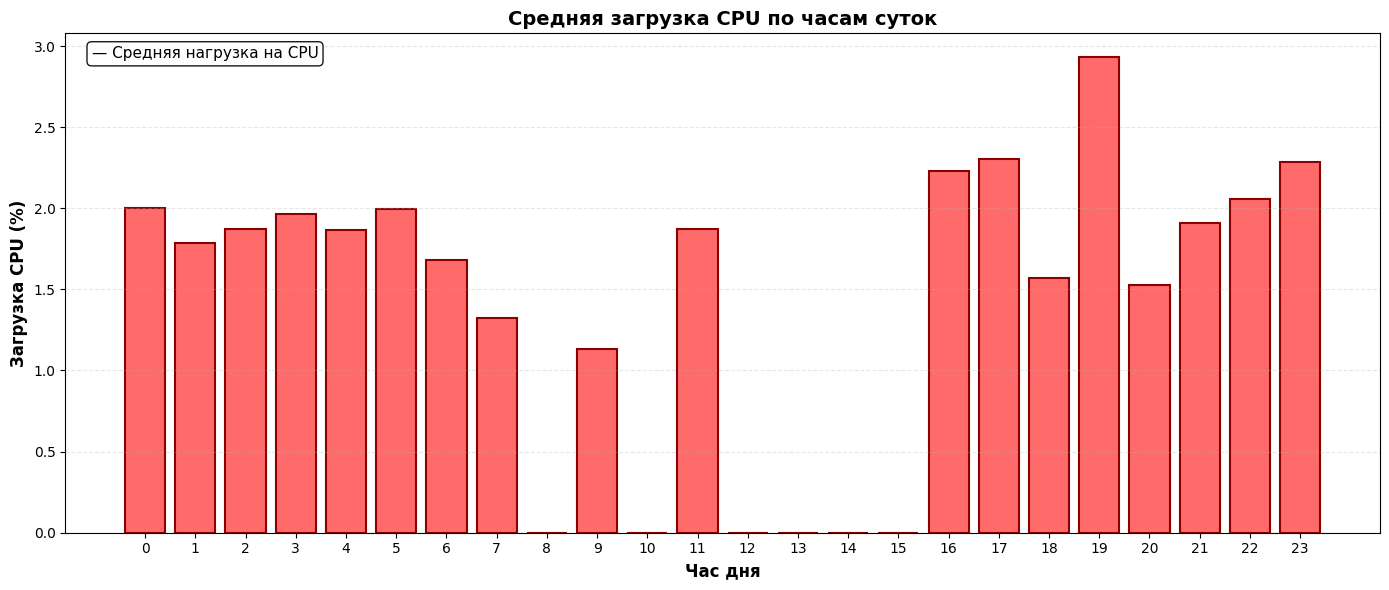

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

# Загрузка данных
df = pd.read_csv('Data/Dataset.csv')

# Преобразование временных меток в часы
df['hour'] = (df['start_time'] / (1000000 * 3600)) % 24

# Функция для извлечения CPU из JSON-строки
def extract_cpu_usage(usage_str):
    try:
        # Преобразуем строку в словарь
        if isinstance(usage_str, str):
            usage_dict = ast.literal_eval(usage_str)
            return usage_dict.get('cpus', 0)
    except:
        pass
    return 0

# Извлекаем среднее использование CPU
df['cpu_avg'] = df['average_usage'].apply(extract_cpu_usage)

# Группируем по часам и считаем среднюю загрузку CPU
hourly_cpu = df.groupby(df['hour'].astype(int))['cpu_avg'].mean().reset_index()
hourly_cpu.columns = ['hour', 'avg_cpu']

# Заполняем все часы
all_hours = np.arange(24)
cpu_by_hour = []

for h in all_hours:
    matching = hourly_cpu[hourly_cpu['hour'] == h]
    if len(matching) > 0:
        cpu_by_hour.append(matching['avg_cpu'].values[0] * 100)  # в процентах
    else:
        cpu_by_hour.append(0)

# Построение графика
plt.figure(figsize=(14, 6))
bars = plt.bar(all_hours, cpu_by_hour, color='#FF6B6B', edgecolor='#8B0000', linewidth=1.5)

plt.title('Средняя загрузка CPU по часам суток', fontsize=14, fontweight='bold')
plt.xlabel('Час дня', fontsize=12, fontweight='bold')
plt.ylabel('Загрузка CPU (%)', fontsize=12, fontweight='bold')
plt.xticks(all_hours, [str(h) for h in all_hours])
plt.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.text(0.02, 0.95, '— Средняя нагрузка на CPU', 
         transform=plt.gca().transAxes, fontsize=11,
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

plt.tight_layout()
plt.savefig('cpu_load_profile.png', dpi=300)
plt.show()

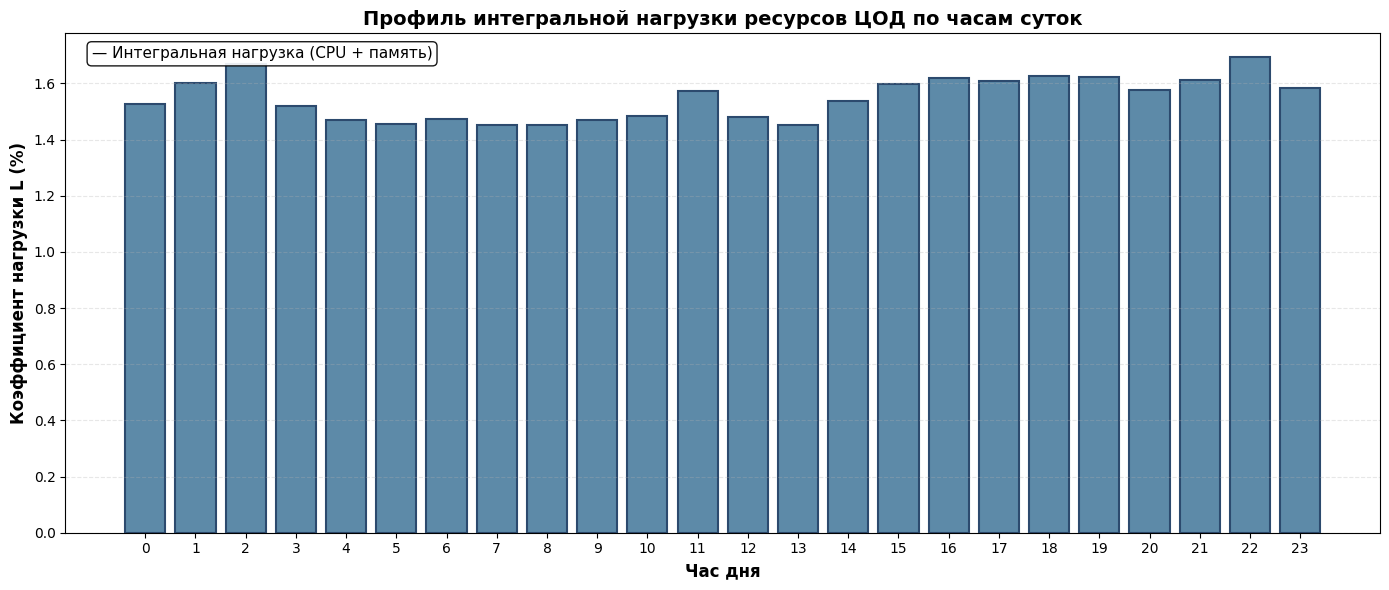

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import ast

df = pd.read_csv('Data/Dataset-24.csv')
df['hour'] = (df['start_time'] / (1000000 * 3600)) % 24

def extract_resources(row):
    try:
        avg_usage = ast.literal_eval(row['average_usage']) if isinstance(row['average_usage'], str) else {}
        cpu = avg_usage.get('cpus', 0)
        memory = avg_usage.get('memory', 0)
        assigned = row['assigned_memory'] if row['assigned_memory'] > 0 else 1
        
        # формула L = (CPU + (MEMORY/ASSIGNED)) / 2
        l_value = (cpu + (memory / assigned)) / 2
        return l_value
    except:
        return 0

df['load_factor'] = df.apply(extract_resources, axis=1)

# Группировка по часам
hourly_load = df.groupby(df['hour'].astype(int))['load_factor'].mean().reset_index()
hourly_load.columns = ['hour', 'avg_load']

all_hours = np.arange(24)
load_by_hour = []

for h in all_hours:
    matching = hourly_load[hourly_load['hour'] == h]
    if len(matching) > 0:
        load_by_hour.append(matching['avg_load'].values[0] * 100)  # в процентах
    else:
        load_by_hour.append(0)

plt.figure(figsize=(14, 6))
bars = plt.bar(all_hours, load_by_hour, color='#5D8AA8', edgecolor='#2C4A6E', linewidth=1.5)

plt.title('Профиль интегральной нагрузки ресурсов ЦОД по часам суток', fontsize=14, fontweight='bold')
plt.xlabel('Час дня', fontsize=12, fontweight='bold')
plt.ylabel('Коэффициент нагрузки L (%)', fontsize=12, fontweight='bold')
plt.xticks(all_hours, [str(h) for h in all_hours])
plt.grid(True, alpha=0.3, axis='y', linestyle='--')

plt.text(0.02, 0.95, '— Интегральная нагрузка (CPU + память)', 
         transform=plt.gca().transAxes, fontsize=11,
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.9))

plt.tight_layout()
plt.savefig('integral_load_profile.png', dpi=300)
plt.show()